In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, roc_auc_score, RocCurveDisplay
import math
import numpy as np
import seaborn as sns
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import confusion_matrix, roc_auc_score, RocCurveDisplay


In [ ]:
train = pd.read_csv('../data/aps_failure_training_set.csv', skiprows=20, na_values="na")
test = pd.read_csv('../data/aps_failure_test_set.csv', skiprows=20, na_values="na")


## b)

There are a few different methods of which we can fill in missing/NA values, such as mean, median, or using a machine learning model. Because we have a large amount of data, it is the safest bet to fill those values with the median, in the case that the data is skewed and irt would be much faster and more interpretable than a model.

In [3]:
feature_cols = train.columns.drop("class")

train[feature_cols] = train[feature_cols].fillna(train[feature_cols].median())

test[feature_cols] = test[feature_cols].fillna(test[feature_cols].median())

In [4]:
train

,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,0.0,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,...,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,neg,33058,0.0,0.000000e+00,126.0,0.0,0.0,0.0,0.0,0.0,...,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,neg,41040,0.0,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,...,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,neg,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,...,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,neg,60874,0.0,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,...,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59995,neg,153002,0.0,6.640000e+02,186.0,0.0,0.0,0.0,0.0,0.0,...,998500.0,566884.0,1290398.0,1218244.0,1019768.0,717762.0,898642.0,28588.0,0.0,0.0
59996,neg,2286,0.0,2.130707e+09,224.0,0.0,0.0,0.0,0.0,0.0,...,10578.0,6760.0,21126.0,68424.0,136.0,0.0,0.0,0.0,0.0,0.0
59997,neg,112,0.0,2.130706e+09,18.0,0.0,0.0,0.0,0.0,0.0,...,792.0,386.0,452.0,144.0,146.0,2622.0,0.0,0.0,0.0,0.0
59998,neg,80292,0.0,2.130706e+09,494.0,0.0,0.0,0.0,0.0,0.0,...,699352.0,222654.0,347378.0,225724.0,194440.0,165070.0,802280.0,388422.0,0.0,0.0


In [5]:
test

,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,60,0.0,2.000000e+01,12.0,0.0,0.0,0.0,0.0,0.0,...,1098.0,138.0,412.0,654.0,78.0,88.0,0.0,0.0,0.0,0.0
1,neg,82,0.0,6.800000e+01,40.0,0.0,0.0,0.0,0.0,0.0,...,1068.0,276.0,1620.0,116.0,86.0,462.0,0.0,0.0,0.0,0.0
2,neg,66002,2.0,2.120000e+02,112.0,0.0,0.0,0.0,0.0,0.0,...,495076.0,380368.0,440134.0,269556.0,1315022.0,153680.0,516.0,0.0,0.0,0.0
3,neg,59816,0.0,1.010000e+03,936.0,0.0,0.0,0.0,0.0,0.0,...,540820.0,243270.0,483302.0,485332.0,431376.0,210074.0,281662.0,3232.0,0.0,0.0
4,neg,1814,0.0,1.560000e+02,140.0,0.0,0.0,0.0,0.0,0.0,...,7646.0,4144.0,18466.0,49782.0,3176.0,482.0,76.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15995,neg,81852,0.0,2.130706e+09,892.0,0.0,0.0,0.0,0.0,0.0,...,632658.0,273242.0,510354.0,373918.0,349840.0,317840.0,960024.0,25566.0,0.0,0.0
15996,neg,18,0.0,5.200000e+01,46.0,8.0,26.0,0.0,0.0,0.0,...,266.0,44.0,46.0,14.0,2.0,0.0,0.0,0.0,0.0,0.0
15997,neg,79636,0.0,1.670000e+03,1518.0,0.0,0.0,0.0,0.0,0.0,...,806832.0,449962.0,778826.0,581558.0,375498.0,222866.0,358934.0,19548.0,0.0,0.0
15998,neg,110,0.0,3.600000e+01,32.0,0.0,0.0,0.0,0.0,0.0,...,588.0,210.0,180.0,544.0,1004.0,1338.0,74.0,0.0,0.0,0.0


In [6]:
cv_train = train.std(numeric_only=True) / train.mean(numeric_only=True)

print(cv_train)


aa_000      2.450938
ab_000     10.383494
ac_000      2.310241
ad_000    244.322816
ae_000     24.200137
             ...    
ee_007      5.012754
ee_008      3.259079
ee_009      5.691612
ef_000     49.366659
eg_000     42.481747
Length: 170, dtype: float64


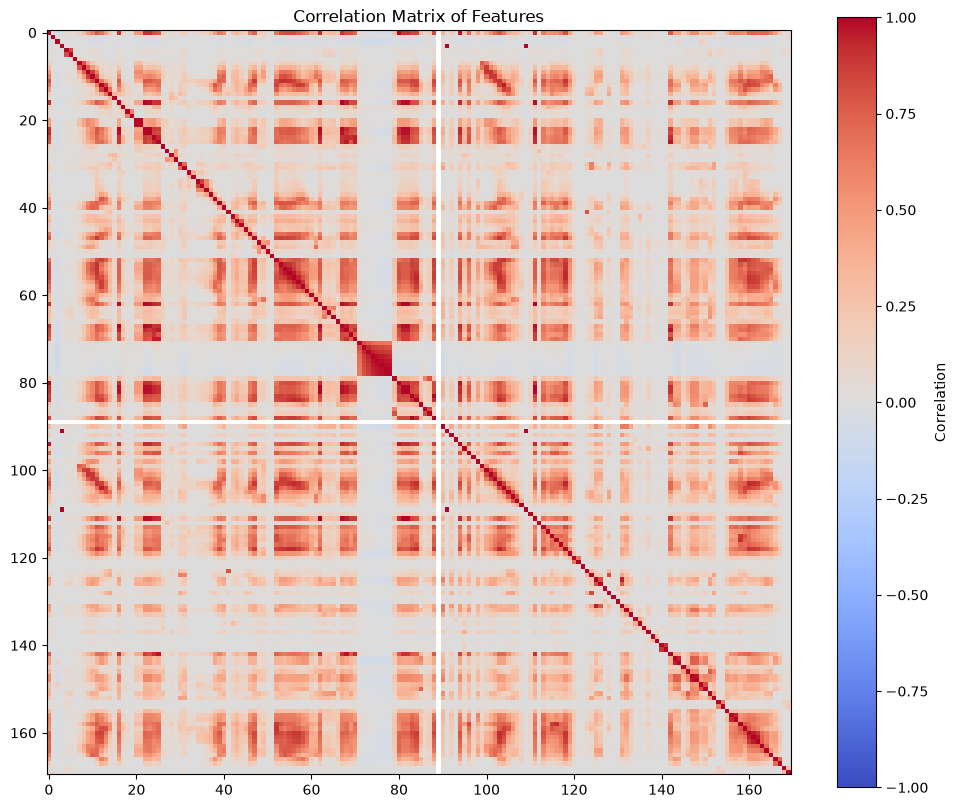

In [7]:
corr = train.corr(numeric_only=True)

plt.figure(figsize=(12, 10))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.title("Correlation Matrix of Features")
plt.show()

In [ ]:
k = int(math.floor(math.sqrt(170)))     
top = cv_train.sort_values(ascending=False).head(k).index


['cf_000', 'co_000', 'ad_000', 'cs_009', 'dh_000', 'dj_000', 'ag_000', 'as_000', 'ay_009', 'ak_000', 'az_009', 'ch_000', 'au_000']


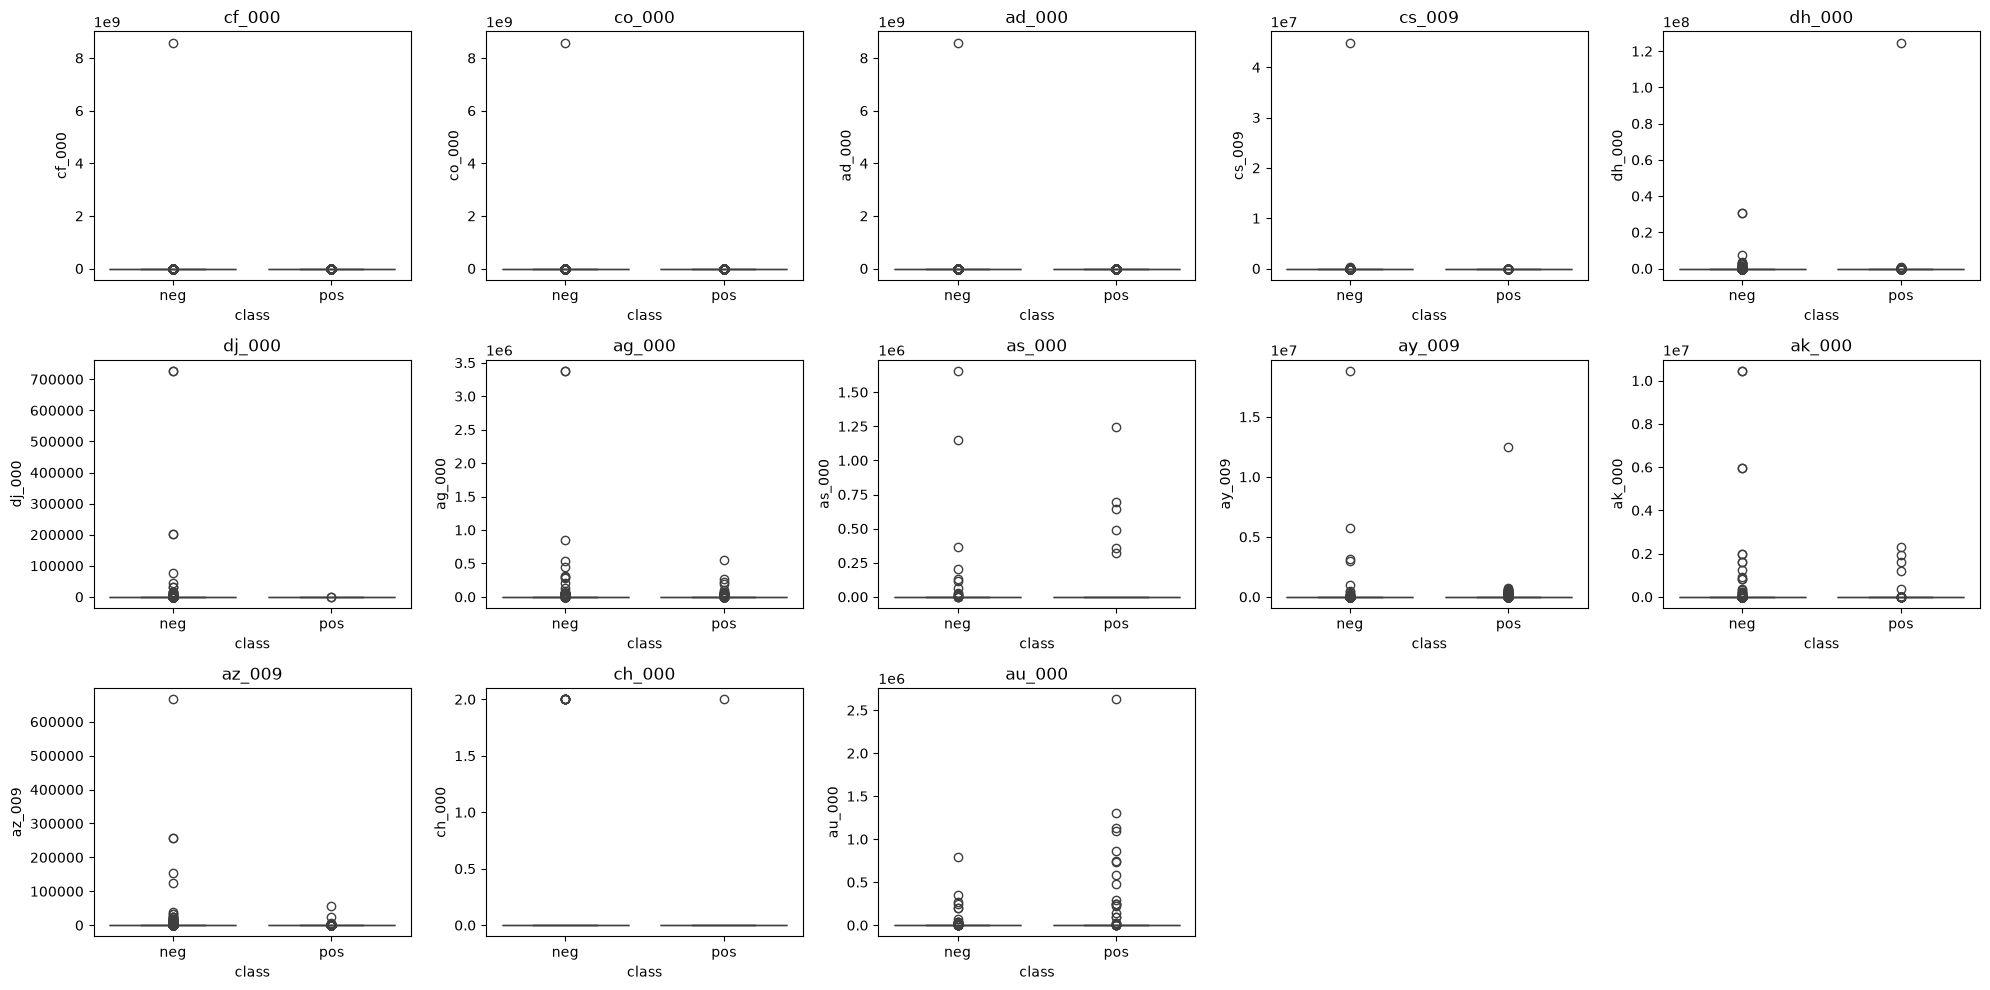

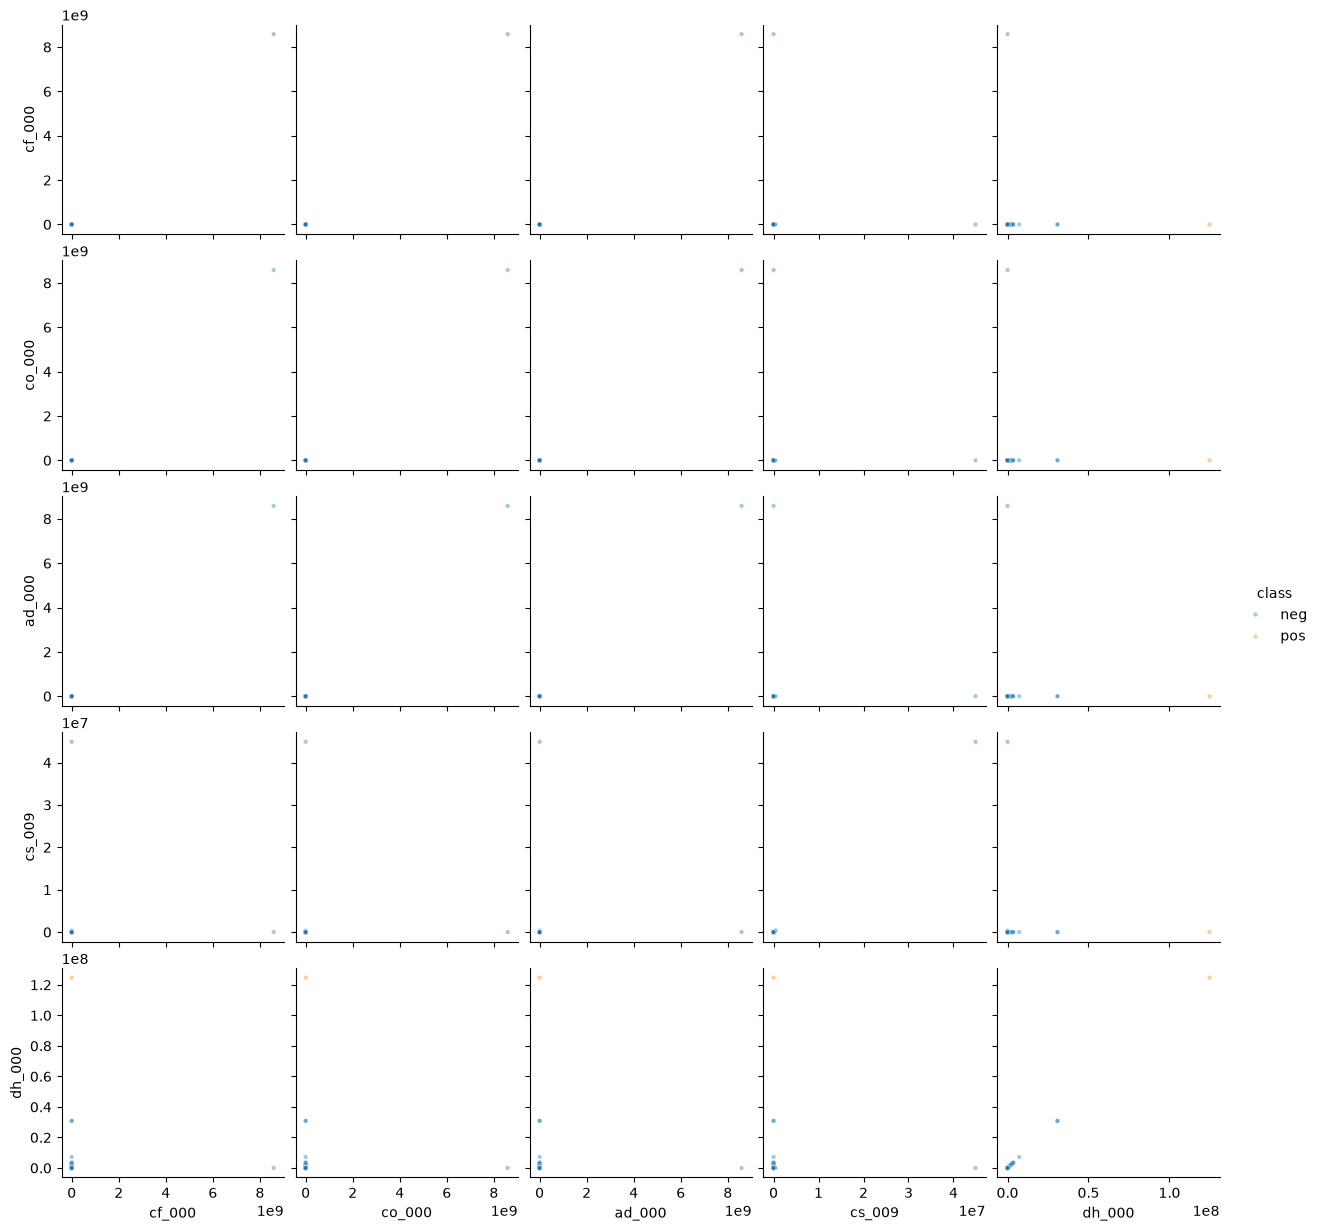

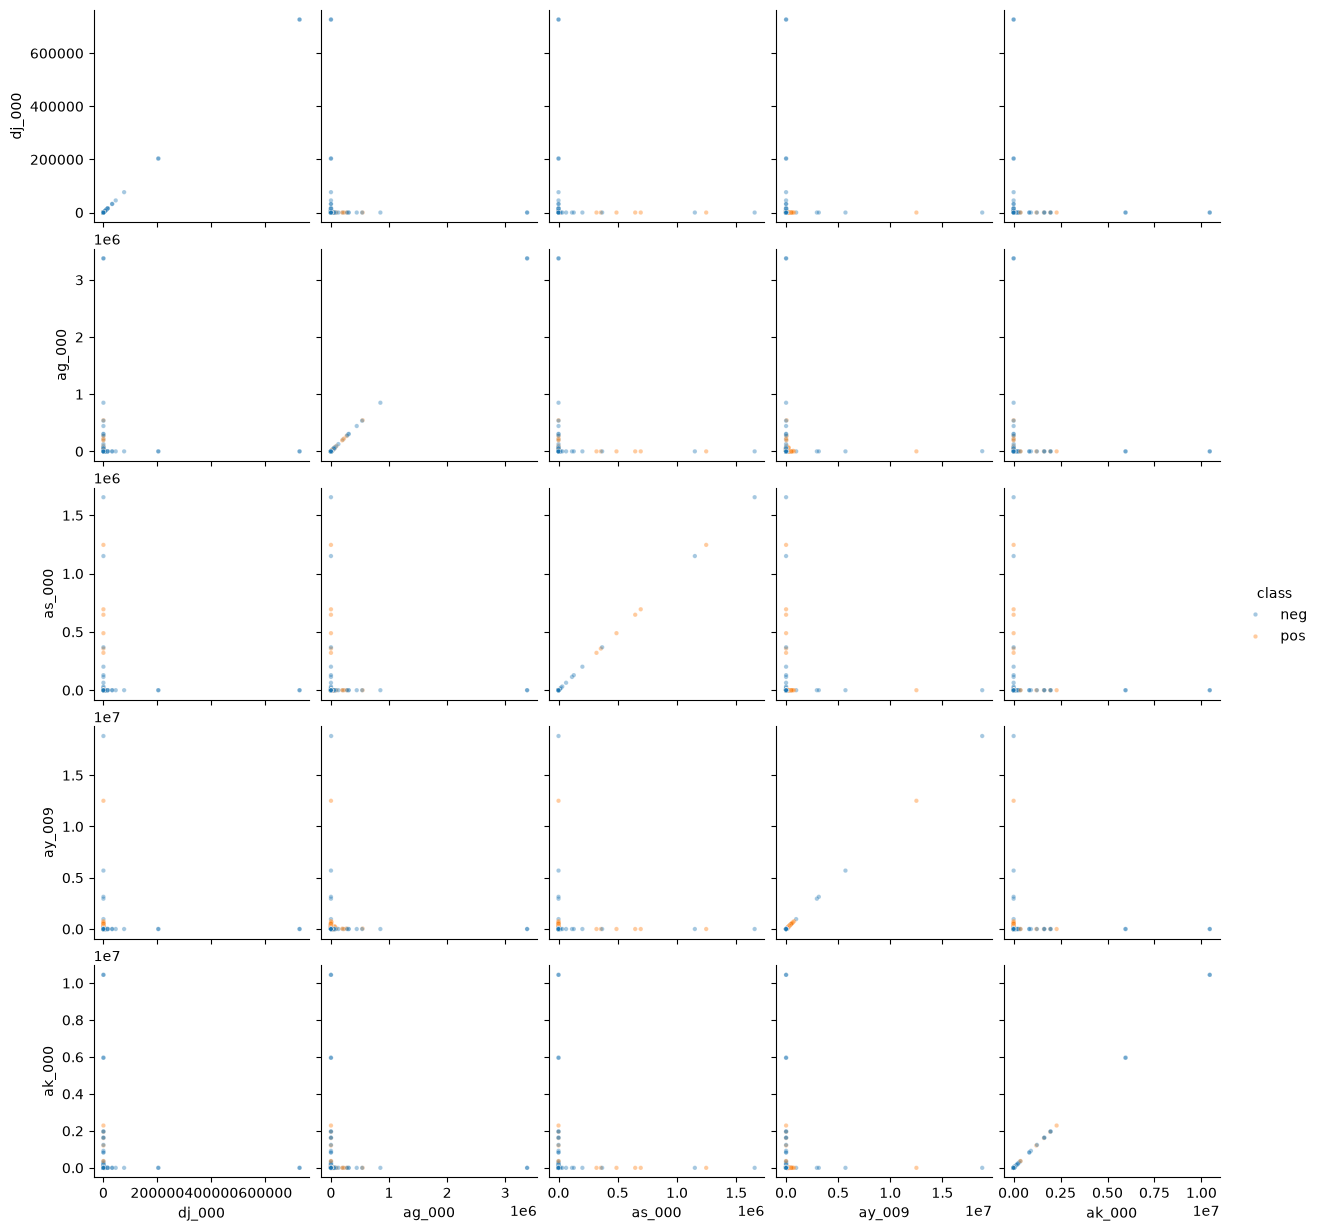

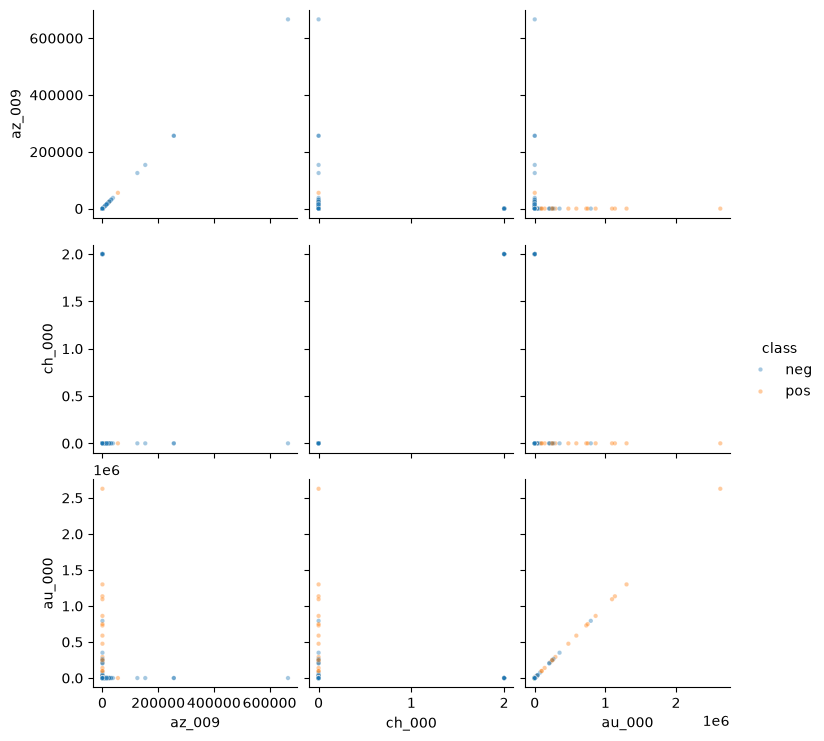

In [10]:
fig, axes = plt.subplots(3, 5, figsize=(20, 10))
for ax, col in zip(axes.ravel(), top):
    sns.boxplot(x="class", y=col, data=train, ax=ax)
    ax.set_title(col)
for ax in axes.ravel()[len(top):]:
    ax.axis("off")
plt.tight_layout()
plt.show()


top = top.tolist()

for i in range(0, 13, 5):
    cols = top[i:i+5]
    sns.pairplot(train[cols + ["class"]], hue="class", diag_kind=None,
                 plot_kws={"alpha": 0.4, "s": 10})
    plt.show()

Theres not tons to conclude from these graphs as the data is condessed into corners and the sides of the graphs. There are some graphs that we can see seperation between the neg and pos values, but not significantly.

In [ ]:
train[train["class"]=="neg"].shape

(59000, 171)

In [ ]:
train[train["class"]=="pos"].shape

(1000, 171)

This dataset is very imbalances, as the amount in the training set that are neg is 59000 and the amount posutive is 1000.

# c)

Train:
 [[59000     0]
 [    1   999]]
Test:
 [[15610    15]
 [  106   269]]
Train AUC: 1.0
Test AUC: 0.9927662079999999
Train error: 1.666666666666483e-05
Test error: 0.0075625000000000275
OOB error: 0.006116666666666659


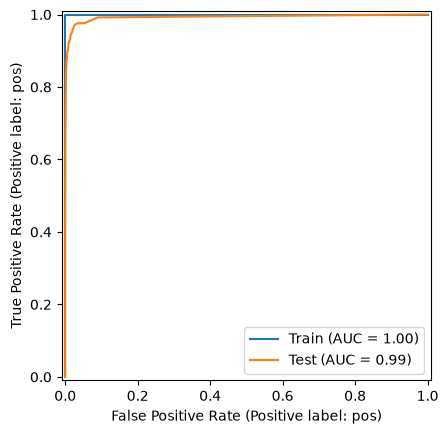

In [ ]:


X_train = train.drop(columns="class")
y_train = train["class"]
X_test = test.drop(columns="class")
y_test = test["class"]

rf = RandomForestClassifier(n_estimators=100, oob_score=True, n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)

# Confusion matrices
print("Train:\n", confusion_matrix(y_train, rf.predict(X_train)))
print("Test:\n", confusion_matrix(y_test, rf.predict(X_test)))

# AUC
print("Train AUC:", roc_auc_score(y_train, rf.predict_proba(X_train)[:, 1]))
print("Test AUC:", roc_auc_score(y_test, rf.predict_proba(X_test)[:, 1]))

# Misclassification (error) rates
print("Train error:", 1 - rf.score(X_train, y_train))
print("Test error:", 1 - rf.score(X_test, y_test))
print("OOB error:", 1 - rf.oob_score_)

# ROC curves on one plot
disp = RocCurveDisplay.from_estimator(rf, X_train, y_train, name="Train")
RocCurveDisplay.from_estimator(rf, X_test, y_test, name="Test", ax=disp.ax_)

# d)

Use class weighting

Train:
 [[59000     0]
 [    1   999]]
Test:
 [[15608    17]
 [  158   217]]
Train AUC: 1.0
Test AUC: 0.9891584853333333
Train error: 1.666666666666483e-05
Test error: 0.010937500000000044
OOB error: 0.008033333333333337


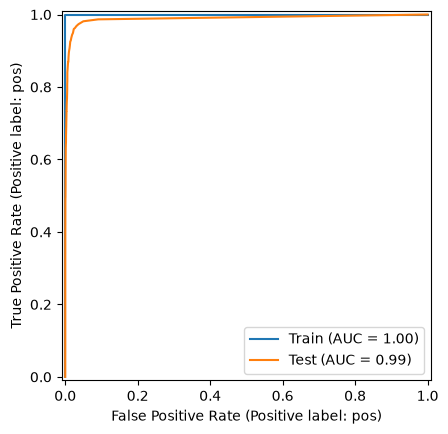

In [ ]:
rf_bal = RandomForestClassifier(n_estimators=100, oob_score=True, n_jobs=-1,
                                random_state=42, class_weight="balanced_subsample")
rf_bal.fit(X_train, y_train)

print("Train:\n", confusion_matrix(y_train, rf_bal.predict(X_train)))
print("Test:\n", confusion_matrix(y_test, rf_bal.predict(X_test)))

print("Train AUC:", roc_auc_score(y_train, rf_bal.predict_proba(X_train)[:, 1]))
print("Test AUC:", roc_auc_score(y_test, rf_bal.predict_proba(X_test)[:, 1]))

print("Train error:", 1 - rf_bal.score(X_train, y_train))
print("Test error:", 1 - rf_bal.score(X_test, y_test))
print("OOB error:", 1 - rf_bal.oob_score_)

disp = RocCurveDisplay.from_estimator(rf_bal, X_train, y_train, name="Train")
RocCurveDisplay.from_estimator(rf_bal, X_test, y_test, name="Test", ax=disp.ax_)

Seems to be very similar results, train AUC==1 for each and test AUC==0.99 for each. The train and test matrices for both are very similar. THe main difference I see is with the test error and OOB error, both have slightly increased test error from 0.0075 to 0.01 and OOB error from 0.006 to 0.008.

# e)

Best alpha: 0.1
5-fold CV error: 0.005899999999999905
Train error: 1.666666666666483e-05
Test error: 0.006437499999999985
Train:
 [[59000     0]
 [    1   999]]
Test:
 [[15605    20]
 [   83   292]]
Train AUC: 0.9999988474576271
Test AUC: 0.9939623253333334


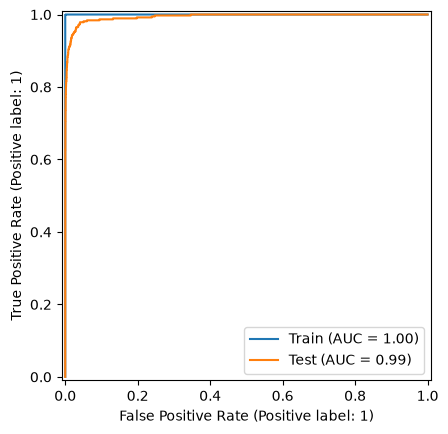

In [ ]:
y_train = y_train.map({"neg": 0, "pos": 1})
y_test = y_test.map({"neg": 0, "pos": 1})

xgb = XGBClassifier(objective="binary:logistic", n_estimators=100, tree_method="hist", n_jobs=-1, random_state=42)

grid = GridSearchCV(xgb, {"reg_alpha": [0, 0.1, 1, 10, 100]}, cv=5, scoring="accuracy", n_jobs=1)
grid.fit(X_train, y_train)

best = grid.best_estimator_
print("Best alpha:", grid.best_params_["reg_alpha"])
print("5-fold CV error:", 1 - grid.best_score_)
print("Train error:", 1 - best.score(X_train, y_train))
print("Test error:", 1 - best.score(X_test, y_test))

# Confusion matrices and AUC
print("Train:\n", confusion_matrix(y_train, best.predict(X_train)))
print("Test:\n", confusion_matrix(y_test, best.predict(X_test)))
print("Train AUC:", roc_auc_score(y_train, best.predict_proba(X_train)[:, 1]))
print("Test AUC:", roc_auc_score(y_test, best.predict_proba(X_test)[:, 1]))

# ROC curves
disp = RocCurveDisplay.from_estimator(best, X_train, y_train, name="Train")
RocCurveDisplay.from_estimator(best, X_test, y_test, name="Test", ax=disp.ax_)

Best alpha: 1
5-fold CV error: 0.006333333333333302
Train error: 1.666666666666483e-05
Test error: 0.007937500000000042
Train:
 [[59000     0]
 [    1   999]]
Test:
 [[15554    71]
 [   56   319]]
Train AUC: 0.9999762118644068
Test AUC: 0.9944634026666667


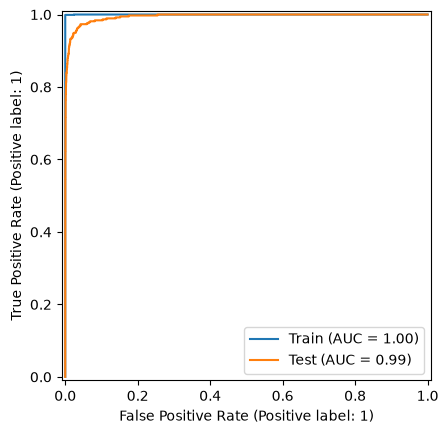

In [ ]:

pipe = Pipeline([
    ("smote", SMOTE(random_state=42)),
    ("xgb", XGBClassifier(objective="binary:logistic", n_estimators=100,
                          tree_method="hist", n_jobs=-1, random_state=42)),
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid = GridSearchCV(pipe, {"xgb__reg_alpha": [0, 0.1, 1, 10, 100]},
                    cv=cv, scoring="accuracy", n_jobs=1)
grid.fit(X_train, y_train)   # SMOTE runs inside each fold, on the training part only

best = grid.best_estimator_  # refit on the full training set, with SMOTE applied once
print("Best alpha:", grid.best_params_["xgb__reg_alpha"])
print("5-fold CV error:", 1 - grid.best_score_)
print("Train error:", 1 - best.score(X_train, y_train))
print("Test error:", 1 - best.score(X_test, y_test))

print("Train:\n", confusion_matrix(y_train, best.predict(X_train)))
print("Test:\n", confusion_matrix(y_test, best.predict(X_test)))
print("Train AUC:", roc_auc_score(y_train, best.predict_proba(X_train)[:, 1]))
print("Test AUC:", roc_auc_score(y_test, best.predict_proba(X_test)[:, 1]))

disp = RocCurveDisplay.from_estimator(best, X_train, y_train, name="Train")
RocCurveDisplay.from_estimator(best, X_test, y_test, name="Test", ax=disp.ax_)

SMOTE cut missed failures from 83 to 56 but raised false alarms from 20 to 71, so the overall test error rose slightly. This is expected because the data is about 98% negative. AUC barely changed, so SMOTE mainly shifted the balance between false negatives and false positives. If missed failures are costlier, the SMOTE model is preferable.

# 2

As we increase s from 0, the training RSS will:
i. Increase initially, and then eventually start decreasing in an inverted U shape.

ii. Decrease initially, and then eventually start increasing in a U shape.

iii. Steadily increase.

iv. Steadily decrease.

v. Remain constant.

(a) iv. Steadily decrease.


(b) Repeat (a) for test RSS.  ii. Decrease initially, and then eventually start increasing in a U shape.


(c) Repeat (a) for variance.   iii. Steadily increase.

(d) Repeat (a) for (squared) bias. iv. Steadily decrease.

(e) Repeat (a) for the irreducible error. v. Remain constant.

# 3

It is well-known that ridge regression tends to give similar coeﬀicient values to correlated variables, whereas the lasso may give quite different coeﬀicient values to correlated variables. We will now explore this property in a very simple setting. Suppose that n = 2, p = 2, x11 = x12, x21 = x22. Furthermore, suppose that y1 + y2 = 0 and x11 + x21 = 0 and x12 + x22 = 0, so that the estimate for the intercept in a least squares, ridge regression, or lasso model is zero:ˆβ0 = 0.
(a) Write out the ridge regression optimization problem in this setting.

(y1 − (β1 + β2)x1)^2 + (y2 − (β1 + β2)x2)^2 + λ(β1^2 + β2^2)

(b) Argue that in this setting, the ridge coeﬀicient estimates satisfy β̂1 = β̂2.

The RSS term depends on β1 and β2 only through their sum s = β1 + β2. So for any fixed s, the data-fit term is the same, and the optimizer only has to choose how to split s between β1 and β2 to minimize the penalty β1^2 + β2^2.
With β1 + β2 = s fixed, β1^2 + β2^2 is minimized when β1 = β2 = s/2. Therefore, whatever value of s is optimal, the ridge solution has β̂1 = β̂2

(c) Write out the lasso optimization problem in this setting.

(y1 − (β1 + β2)x1)^2 + (y2 − (β1 + β2)x2)^2 + λ(|β1| + |β2|)

(d) Argue that in this setting, the lasso coeﬀicientsˆβ1 andˆβ2 are not unique—in other words, there are many possible solutions to the optimization problem in (c). Describe these solutions.

Unlike ridge, when s (β̂1 + β̂2) is fixed, there is no β̂1 and β̂2 that optimizes the penalty. All values are equal as long as they are the same sign. If s* > 0, the solutions are all points with β1 + β2 = s* and both β1, β2 ≥ 0. If s* < 0, the same thing but with both coefficients ≤ 0. If s* = 0, the only solution is β1 = β2 = 0.


# 4

Suppose we produce ten bootstrapped samples from a data set containing red and green classes. We then apply a classification tree to each bootstrapped sample and, for a specific value of X, produce 10 estimates of P (Class is Red|X): 0.1, 0.15, 0.2, 0.2, 0.55, 0.6, 0.6, 0.65, 0.7, and 0.75. There are two common ways to combine these results together into a single class prediction. One is the majority vote approach discussed in this chapter. The second approach is to classify based on the average probability. In this example, what is the final classification under each of these two approaches?

If we are calculating this using majority, we will sort this into Red and Green. Red: 0.55, 0.6, 0.6, 0.65, 0.7, 0.75 and Green: 0.1, 0.15, 0.2, 0.2. Because Red has 6 and Green has 4, red wins and X is classified as Red.

Using average probability, we will average all of the values: (0.1 + 0.15 + 0.2 + 0.2 + 0.55 + 0.6 + 0.6 + 0.65 + 0.7 + 0.75)/10 = 0.45. Using this method X is classified as green because the average < 0.5

# 5

Here we explore the maximal margin classifier on a toy data set.
Obs. X1 X2 Y
1 3 4 Red
2 2 2 Red
3 4 4 Red
4 1 4 Red
5 2 1 Blue
6 4 3 Blue
7 4 1 Blue


(a) We are given n = 7 observations in p = 2 dimensions. For each observation, there is an associated class label. Sketch the observations.

(b) Sketch the optimal separating hyperplane, and provide the equation for this hyperplane (of the form (9.1)).

Black dashed line
0.5 − X1 + X2 = 0

(c) Describe the classification rule for the maximal margin classifier. It should be something along the lines of “Classify to Red if β0 + β1X1 + β2X2 > 0, and classify to Blue otherwise.” Provide the values for β0, β1, and β2.

Classify to Red if 0.5 − X1 + X2 > 0, and to Blue otherwise. The values are β0 = 0.5, β1 = −1, β2 = 1. Any positive multiple of these also describes the same hyperplane.

(d) On your sketch, indicate the margin for the maximal margin hyperplane.

Shaded purple region between blue dotted line and red dotted line

(e) Indicate the support vectors for the maximal margin classifier.

Black x points

(f) Argue that a slight movement of the seventh observation would not affect the maximal margin hyperplane.

Observation 7 is (4,1). It is not a support vector. It lies well outside the margin: its value 0.5 − 4 + 1 = −2.5 is far from the ±0.5 of the support vectors. The maximal margin hyperplane depends only on the support vectors, so a slight movement of (4,1) that doesn’t carry it into the margin leaves the hyperplane unchanged.

(g) Sketch a hyperplane that is not the optimal separating hyperplane, and provide the equation for this hyperplane.

Green solid line X2=1.2X1-1

(h) Draw an additional observation on the plot so that the two classes are no longer separable by a hyperplane. 

Red circle (3, 1)

![Maximal margin classifier](graph.png)